# Title : Analyzing Sales Data from Multiple File Formats

In [35]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import json

In [36]:
csv = pd.read_csv("/sales_data_sample.csv", encoding="cp1252")

In [37]:
ed = pd.read_excel("/Sample-Sales-Data.xlsx")

In [38]:
with open("/customers.json", "r") as json_file:
    json_data = json.load(json_file)

In [39]:
# Converting JSON data into DataFrame
json_df = pd.json_normalize(json_data)

In [40]:
# Exploring CSV Dataset
print("CSV DATASET")
print(csv.head())
print(csv.tail())
csv.info()
print(csv.describe(include='all'))
print("Missing Values:\n", csv.isnull().sum())
print("Duplicate Rows:", csv.duplicated().sum())

CSV DATASET
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye  

In [41]:
# Exploring Excel Dataset
print("\nEXCEL DATASET")
print(ed.head())
print(ed.tail())
ed.info()
print(ed.describe(include='all'))
print("Missing Values:\n", ed.isnull().sum())
print("Duplicate Rows:", ed.duplicated().sum())


EXCEL DATASET
   Postcode  Sales_Rep_ID Sales_Rep_Name  Year         Value
0      2121           456           Jane  2011  84219.497311
1      2092           789         Ashish  2012  28322.192268
2      2128           456           Jane  2013  81878.997241
3      2073           123           John  2011  44491.142121
4      2134           789         Ashish  2012  71837.720959
     Postcode  Sales_Rep_ID Sales_Rep_Name  Year         Value
385      2164           123           John  2012  88884.535217
386      2193           456           Jane  2013  79440.290813
387      2031           123           John  2011  65643.689454
388      2130           456           Jane  2012  66247.874869
389      2116           456           Jane  2013   3195.699054
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 390 entries, 0 to 389
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Postcode        390 non-null    int64  
 1

In [42]:
# Exploring JSON Dataset
print("\nJSON DATASET")
print(json_df.head())
json_df.info()
print("Missing Values:\n", json_df.isnull().sum())
print("Duplicate Rows:", json_df.duplicated().sum())


JSON DATASET
   id                   email    first     last  \
0   1  isidro_von@hotmail.com   Torrey     Veum   
1   2  frederique19@gmail.com    Micah  Sanford   
2   3       fredy54@gmail.com   Hollis    Swift   
3   4   braxton29@hotmail.com    Perry  Leffler   
4   5      turner59@gmail.com  Janelle  Hagenes   

                          company                created_at  \
0          Hilll, Mayert and Wolf  2014-12-25T04:06:27.981Z   
1                  Stokes-Reichel  2014-07-03T16:08:17.044Z   
2  Rodriguez, Cartwright and Kuhn  2014-08-18T06:15:16.731Z   
3        Sipes, Feeney and Hansen  2014-07-10T11:31:40.235Z   
4             Lesch and Daughters  2014-04-21T15:05:43.229Z   

                                 country  
0                            Switzerland  
1  Democratic People's Republic of Korea  
2                                Tunisia  
3                                   Chad  
4                              Swaziland  
<class 'pandas.core.frame.DataFrame'>
Rang

In [43]:
# Data Cleaning Operations

# Removing duplicate records
csv = csv.drop_duplicates()
ed = ed.drop_duplicates()
json_df = json_df.drop_duplicates()

In [44]:
# Handling missing values
csv = csv.dropna()
ed = ed.dropna()
json_df = json_df.dropna()

In [45]:
# Checking missing values after cleaning
print("\nMissing Values After Cleaning:")
print("CSV:\n", csv.isnull().sum())
print("Excel:\n", ed.isnull().sum())
print("JSON:\n", json_df.isnull().sum())


Missing Values After Cleaning:
CSV:
 ORDERNUMBER         0
QUANTITYORDERED     0
PRICEEACH           0
ORDERLINENUMBER     0
SALES               0
ORDERDATE           0
STATUS              0
QTR_ID              0
MONTH_ID            0
YEAR_ID             0
PRODUCTLINE         0
MSRP                0
PRODUCTCODE         0
CUSTOMERNAME        0
PHONE               0
ADDRESSLINE1        0
ADDRESSLINE2        0
CITY                0
STATE               0
POSTALCODE          0
COUNTRY             0
TERRITORY           0
CONTACTLASTNAME     0
CONTACTFIRSTNAME    0
DEALSIZE            0
dtype: int64
Excel:
 Postcode          0
Sales_Rep_ID      0
Sales_Rep_Name    0
Year              0
Value             0
dtype: int64
JSON:
 id            0
email         0
first         0
last          0
company       0
created_at    0
country       0
dtype: int64


In [46]:
# Converting Data into a Unified Format

# Checking common columns between CSV and Excel
common_columns = csv.columns.intersection(ed.columns)

In [47]:
# Combining CSV and Excel datasets
unified_data = pd.concat(
    [csv, ed],
    ignore_index=True,
    sort=False
)

In [48]:
print("\nUNIFIED DATASET")
print(unified_data.head())
print(unified_data.info())


UNIFIED DATASET
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0      10223.0             37.0     100.00              1.0  3965.66   
1      10361.0             20.0      72.55             13.0  1451.00   
2      10270.0             21.0     100.00              9.0  4905.39   
3      10347.0             30.0     100.00              1.0  3944.70   
4      10391.0             24.0     100.00              4.0  2416.56   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...    COUNTRY  \
0   2/20/2004 0:00  Shipped     1.0       2.0   2004.0  ...  Australia   
1  12/17/2004 0:00  Shipped     4.0      12.0   2004.0  ...  Australia   
2   7/19/2004 0:00  Shipped     3.0       7.0   2004.0  ...  Australia   
3  11/29/2004 0:00  Shipped     4.0      11.0   2004.0  ...  Australia   
4    3/9/2005 0:00  Shipped     1.0       3.0   2005.0  ...  Australia   

   TERRITORY CONTACTLASTNAME CONTACTFIRSTNAME DEALSIZE Postcode Sales_Rep_ID  \
0       APAC        Fergu

In [49]:
# Data Transformation

# Converting ORDERDATE into datetime format if available
if 'ORDERDATE' in unified_data.columns:
    unified_data['ORDERDATE'] = pd.to_datetime(
        unified_data['ORDERDATE'],
        errors='coerce'
    )

In [50]:
# Creating new variables
if 'SALES' in unified_data.columns:
    unified_data['SALES'] = pd.to_numeric(
        unified_data['SALES'],
        errors='coerce'
    )

In [51]:
# Extracting year and month from order date
if 'ORDERDATE' in unified_data.columns:
    unified_data['YEAR'] = unified_data['ORDERDATE'].dt.year
    unified_data['MONTH'] = unified_data['ORDERDATE'].dt.month

In [52]:
# Splitting customer name if available
if 'CUSTOMERNAME' in unified_data.columns:
    unified_data[['FIRST_NAME', 'LAST_NAME']] = (
        unified_data['CUSTOMERNAME']
        .str.split(' ', n=1, expand=True)
    )

In [53]:
# Merging customer information if a common customer ID exists
if 'CUSTOMERNUMBER' in unified_data.columns and \
   'CUSTOMERNUMBER' in json_df.columns:

    unified_data = pd.merge(
        unified_data,
        json_df,
        on='CUSTOMERNUMBER',
        how='left',
        suffixes=('', '_CUSTOMER')
    )

In [54]:
print("\nTRANSFORMED DATASET")
print(unified_data.head())


TRANSFORMED DATASET
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0      10223.0             37.0     100.00              1.0  3965.66   
1      10361.0             20.0      72.55             13.0  1451.00   
2      10270.0             21.0     100.00              9.0  4905.39   
3      10347.0             30.0     100.00              1.0  3944.70   
4      10391.0             24.0     100.00              4.0  2416.56   

   ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ... DEALSIZE  Postcode  \
0 2004-02-20  Shipped     1.0       2.0   2004.0  ...   Medium       NaN   
1 2004-12-17  Shipped     4.0      12.0   2004.0  ...    Small       NaN   
2 2004-07-19  Shipped     3.0       7.0   2004.0  ...   Medium       NaN   
3 2004-11-29  Shipped     4.0      11.0   2004.0  ...   Medium       NaN   
4 2005-03-09  Shipped     1.0       3.0   2005.0  ...    Small       NaN   

  Sales_Rep_ID Sales_Rep_Name Year Value    YEAR MONTH  FIRST_NAME  \
0          NaN     

In [55]:
# Data Analysis

# Calculating Total Sales
total_sales = unified_data['SALES'].sum()

print("\nTotal Sales:", total_sales)


Total Sales: 506562.51999999996


In [56]:
# Calculating Average Order Value
if 'ORDERNUMBER' in unified_data.columns:
    order_sales = unified_data.groupby(
        'ORDERNUMBER'
    )['SALES'].sum()

    average_order_value = order_sales.mean()

    print("Average Order Value:", average_order_value)

Average Order Value: 38966.347692307696


In [57]:
# Calculating Average Sales
average_sales = unified_data['SALES'].mean()
print("Average Sales:", average_sales)

Average Sales: 3446.0035374149656


In [58]:
# Calculating Sales by Order Number
category_sales = unified_data.groupby(
    'ORDERNUMBER'
)['SALES'].sum()

In [59]:
print("\nSales by Order Number:")
print(category_sales.head())


Sales by Order Number:
ORDERNUMBER
10120.0    50397.66
10125.0     9738.18
10139.0    28397.26
10148.0    47191.76
10169.0    41791.95
Name: SALES, dtype: float64


In [60]:
# Product Category Distribution
if 'PRODUCTLINE' in unified_data.columns:

    category_counts = unified_data['PRODUCTLINE'].value_counts()

    print("\nProduct Category Distribution:")
    print(category_counts)

    category_sales_by_product = unified_data.groupby(
        'PRODUCTLINE'
    )['SALES'].sum()

    print("\nSales by Product Category:")
    print(category_sales_by_product)



Product Category Distribution:
PRODUCTLINE
Classic Cars        46
Vintage Cars        39
Motorcycles         22
Planes              21
Trucks and Buses    18
Ships                1
Name: count, dtype: int64

Sales by Product Category:
PRODUCTLINE
Classic Cars        161870.46
Motorcycles          75476.67
Planes               63772.09
Ships                 1089.36
Trucks and Buses     66020.96
Vintage Cars        138332.98
Name: SALES, dtype: float64


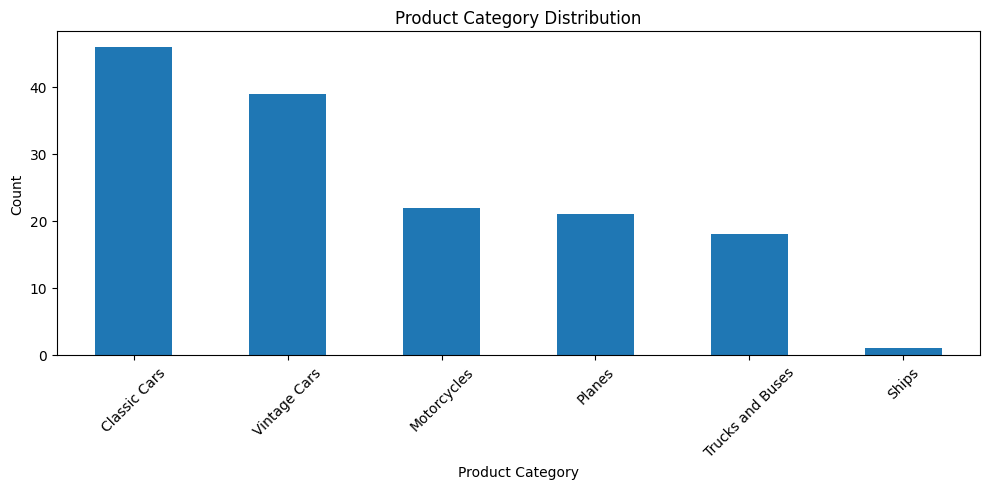

In [61]:
# Data Visualization

# 1. Bar Plot - Product Category Distribution
if 'PRODUCTLINE' in unified_data.columns:

    category_counts.plot(
        kind='bar',
        figsize=(10, 5)
    )

    plt.title('Product Category Distribution')
    plt.xlabel('Product Category')
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


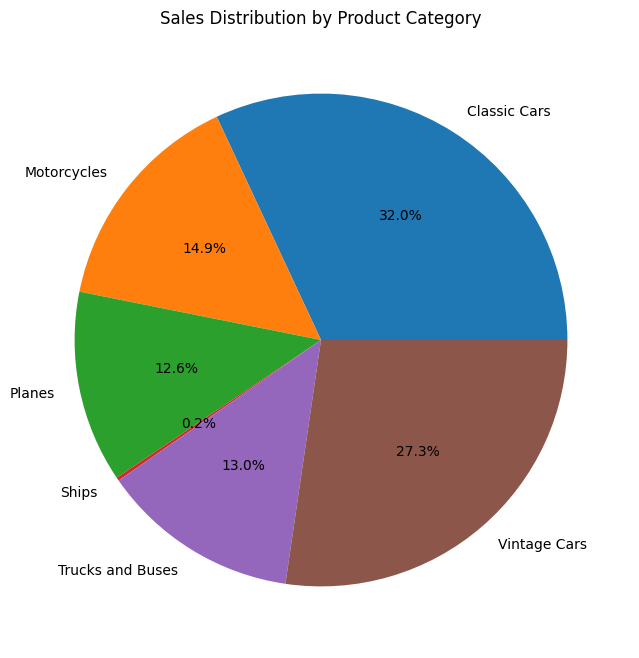

In [62]:
# 2. Pie Chart - Sales by Product Category
if 'PRODUCTLINE' in unified_data.columns:

    category_sales_by_product.plot(
        kind='pie',
        autopct='%1.1f%%',
        figsize=(8, 8)
    )

    plt.title('Sales Distribution by Product Category')
    plt.ylabel('')
    plt.show()


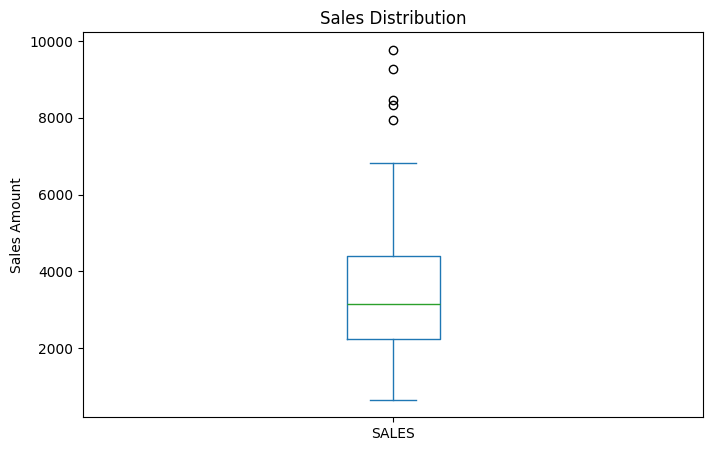

In [63]:
# 3. Box Plot - Sales Distribution
unified_data['SALES'].plot(
    kind='box',
    figsize=(8, 5)
)
plt.title('Sales Distribution')
plt.ylabel('Sales Amount')
plt.show()

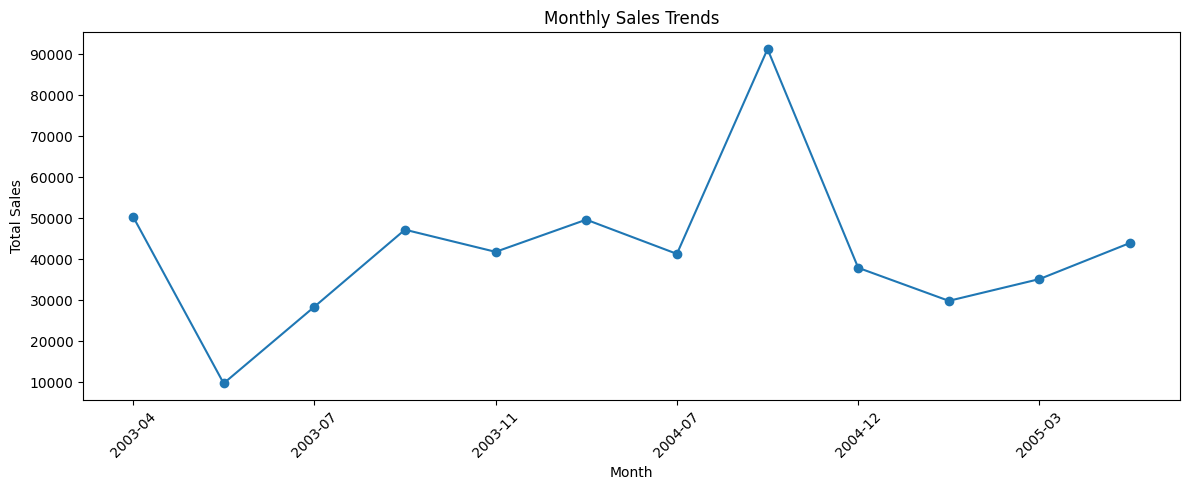

In [64]:
# 4. Line Plot - Sales Trends Over Time
if 'ORDERDATE' in unified_data.columns:

    monthly_sales = unified_data.groupby(
        unified_data['ORDERDATE'].dt.to_period('M')
    )['SALES'].sum()

    monthly_sales.index = monthly_sales.index.astype(str)

    monthly_sales.plot(
        kind='line',
        marker='o',
        figsize=(12, 5)
    )

    plt.title('Monthly Sales Trends')
    plt.xlabel('Month')
    plt.ylabel('Total Sales')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


In [65]:
# Final Dataset Information
print("\nFINAL DATASET INFORMATION")
print(unified_data.info())

print("\nFinal Dataset Shape:", unified_data.shape)


FINAL DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 537 entries, 0 to 536
Data columns (total 34 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   ORDERNUMBER       147 non-null    float64       
 1   QUANTITYORDERED   147 non-null    float64       
 2   PRICEEACH         147 non-null    float64       
 3   ORDERLINENUMBER   147 non-null    float64       
 4   SALES             147 non-null    float64       
 5   ORDERDATE         147 non-null    datetime64[ns]
 6   STATUS            147 non-null    object        
 7   QTR_ID            147 non-null    float64       
 8   MONTH_ID          147 non-null    float64       
 9   YEAR_ID           147 non-null    float64       
 10  PRODUCTLINE       147 non-null    object        
 11  MSRP              147 non-null    float64       
 12  PRODUCTCODE       147 non-null    object        
 13  CUSTOMERNAME      147 non-null    object        
 14 